In [1]:
print("hello lstm")

hello lstm


WINDOW = 10
LSTM units = 8
Dense = 4
Epochs = 200
Batch size = 16

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

load data

In [4]:
df = pd.read_csv("ds18b20_data.csv")

temps = df["temperature_C"].values.reshape(-1, 1)

normalization

In [5]:
scaler = MinMaxScaler()
temps_scaled = scaler.fit_transform(temps)

print("Scaler min:", scaler.data_min_[0])
print("Scaler max:", scaler.data_max_[0])

Scaler min: 7.312
Scaler max: 38.938


seq instance

In [6]:
WINDOW = 10

X = []
y = []

for i in range(len(temps_scaled) - WINDOW):
    X.append(temps_scaled[i:i+WINDOW])
    y.append(temps_scaled[i+WINDOW])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2862, 10, 1)
y shape: (2862, 1)


train-test-valid split

In [7]:
split = int(0.8 * len(X))

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

tinyLSTM model train

In [8]:
model = Sequential([
    Input(shape=(WINDOW, 1)),
    LSTM(8),
    Dense(4, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 8)              │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361 (1.41 KB)

 Trainable params: 361 (1.41 KB)

 Non-trainable params: 0 (0.00 B)

training

In [11]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=25,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/200


115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.7326e-04 - mae: 0.0065 - val_loss: 2.8757e-05 - val_mae: 0.0052
Epoch 2/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.5713e-04 - mae: 0.0061 - val_loss: 5.0255e-06 - val_mae: 0.0020
Epoch 3/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.5213e-04 - mae: 0.0061 - val_loss: 2.1753e-05 - val_mae: 0.0045
Epoch 4/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.6475e-04 - mae: 0.0067 - val_loss: 0.0011 - val_mae: 0.0337
Epoch 5/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.7506e-04 - mae: 0.0069 - val_loss: 1.2435e-05 - val_mae: 0.0033
Epoch 6/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.3603e-04 - mae: 0.0055 - val_loss: 6.9857e-06 - val_mae: 0.0024
Epoch 7/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 1.3963e-04 - mae: 0.0061 - val_loss: 1.5704e-06 - val_mae: 9.6331e-04
Epoch 8/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.4121e-04 - mae: 0.0058 - val_loss: 1.8808e-05 - val_mae: 0.0

predict

In [12]:
y_pred_scaled = model.predict(X_test)

y_test_actual = scaler.inverse_transform(y_test)
y_pred_actual = scaler.inverse_transform(y_pred_scaled)

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step


eval metrics

In [15]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

mae = mean_absolute_error(y_test_actual, y_pred_actual)
mse = mean_squared_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_test_actual, y_pred_actual) * 100
r2 = r2_score(y_test_actual, y_pred_actual)

print(f"MAE : {mae:.6f} °C")
print(f"MSE : {mse:.6f}")
print(f"RMSE: {rmse:.6f} °C")
print(f"MAPE: {mape:.3f} %")
print(f"R²  : {r2:.6f}")

MAE : 0.090259 °C
MSE : 0.009926
RMSE: 0.099631 °C
MAPE: 0.383 %
R²  : 0.892878


graphs

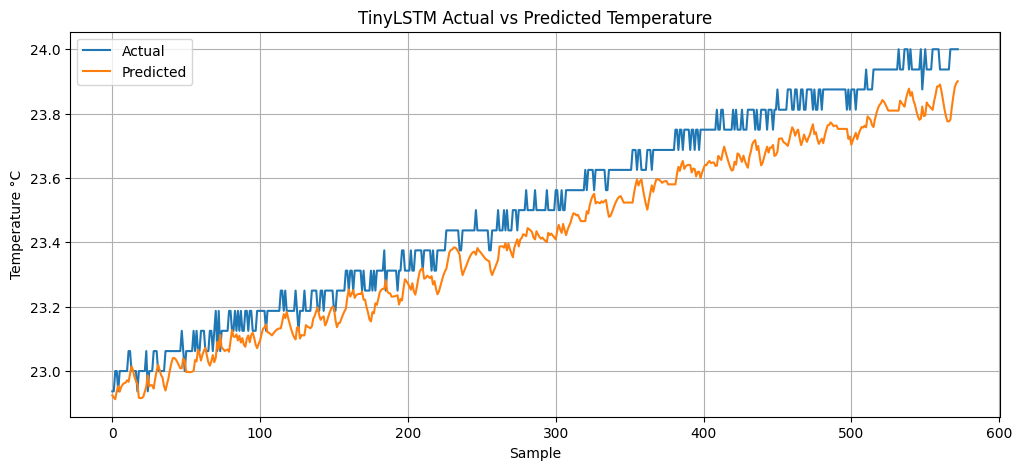

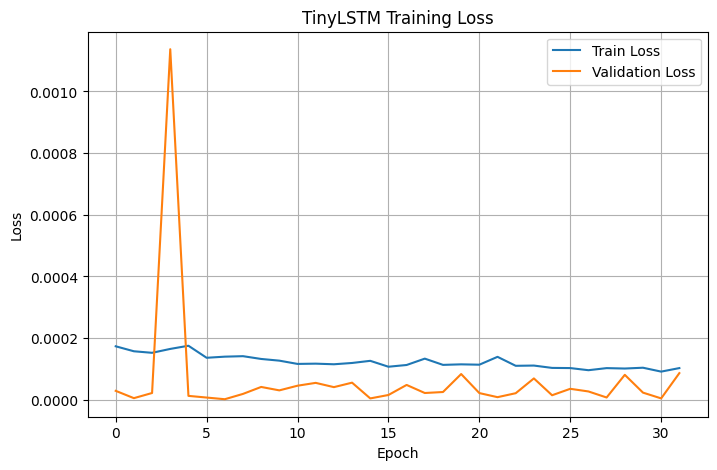

In [14]:
plt.figure(figsize=(12,5))
plt.plot(y_test_actual, label="Actual")
plt.plot(y_pred_actual, label="Predicted")
plt.title("TinyLSTM Actual vs Predicted Temperature")
plt.xlabel("Sample")
plt.ylabel("Temperature °C")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("TinyLSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

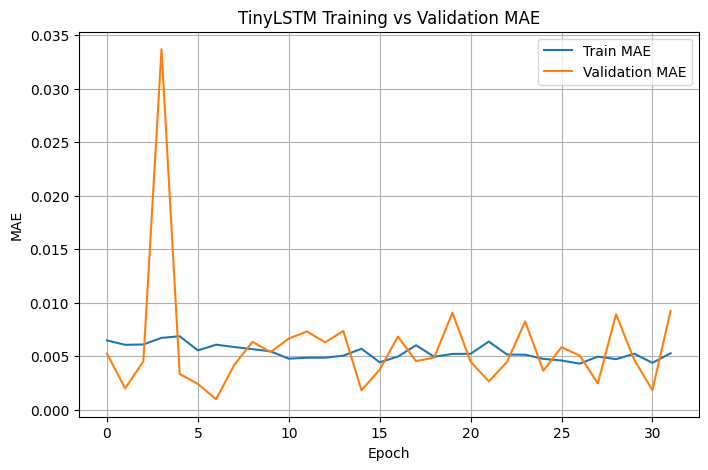

In [16]:
plt.figure(figsize=(8,5))

plt.plot(history.history["mae"], label="Train MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.title("TinyLSTM Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.grid(True)
plt.legend()

plt.show()

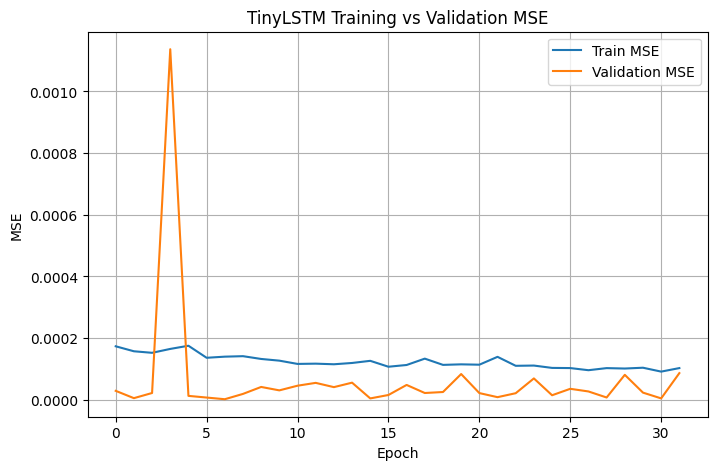

In [17]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Train MSE")
plt.plot(history.history["val_loss"], label="Validation MSE")

plt.title("TinyLSTM Training vs Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.grid(True)
plt.legend()

plt.show()

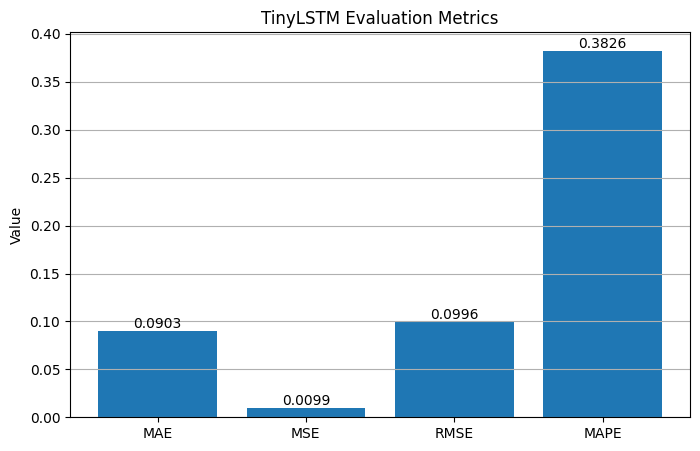

In [18]:
metrics = [mae, mse, rmse, mape]

labels = ["MAE", "MSE", "RMSE", "MAPE"]

plt.figure(figsize=(8,5))
plt.bar(labels, metrics)

plt.title("TinyLSTM Evaluation Metrics")
plt.ylabel("Value")
plt.grid(axis="y")

for i, v in enumerate(metrics):
    plt.text(i, v, f"{v:.4f}", ha='center', va='bottom')

plt.show()

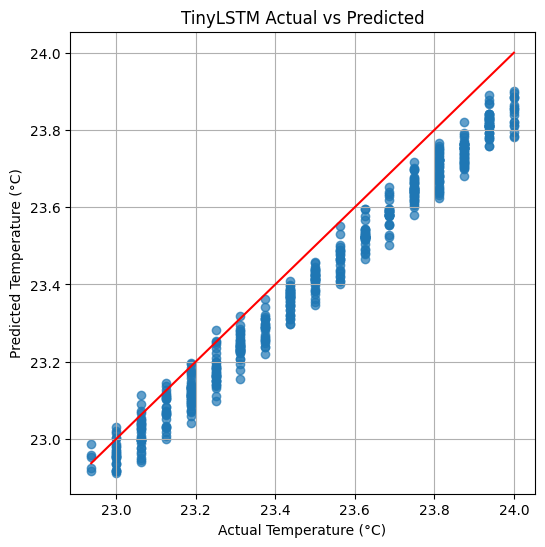

In [19]:
plt.figure(figsize=(6,6))

plt.scatter(y_test_actual,
            y_pred_actual,
            alpha=0.7)

plt.plot(
    [y_test_actual.min(), y_test_actual.max()],
    [y_test_actual.min(), y_test_actual.max()],
    'r'
)

plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.title("TinyLSTM Actual vs Predicted")

plt.grid(True)
plt.show()

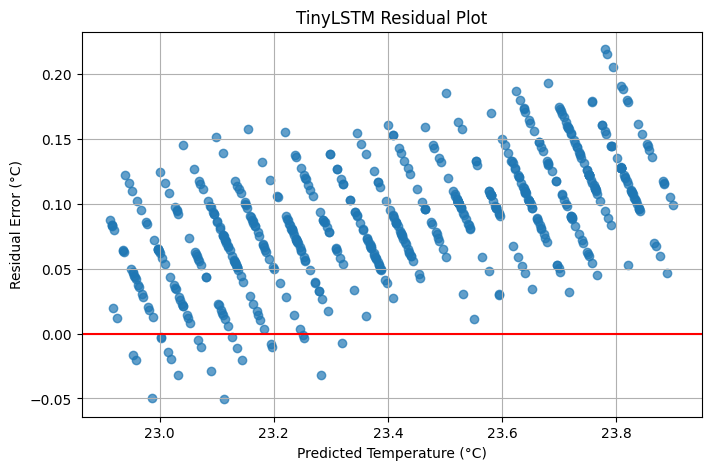

In [20]:
residuals = y_test_actual.flatten() - y_pred_actual.flatten()

plt.figure(figsize=(8,5))

plt.scatter(
    y_pred_actual,
    residuals,
    alpha=0.7
)

plt.axhline(0, color='red')

plt.xlabel("Predicted Temperature (°C)")
plt.ylabel("Residual Error (°C)")
plt.title("TinyLSTM Residual Plot")

plt.grid(True)
plt.show()

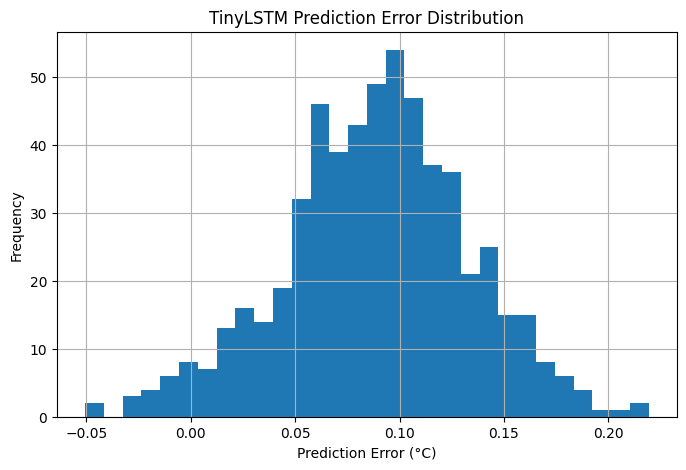

In [21]:
plt.figure(figsize=(8,5))

plt.hist(residuals,
         bins=30)

plt.xlabel("Prediction Error (°C)")
plt.ylabel("Frequency")
plt.title("TinyLSTM Prediction Error Distribution")

plt.grid(True)
plt.show()

90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


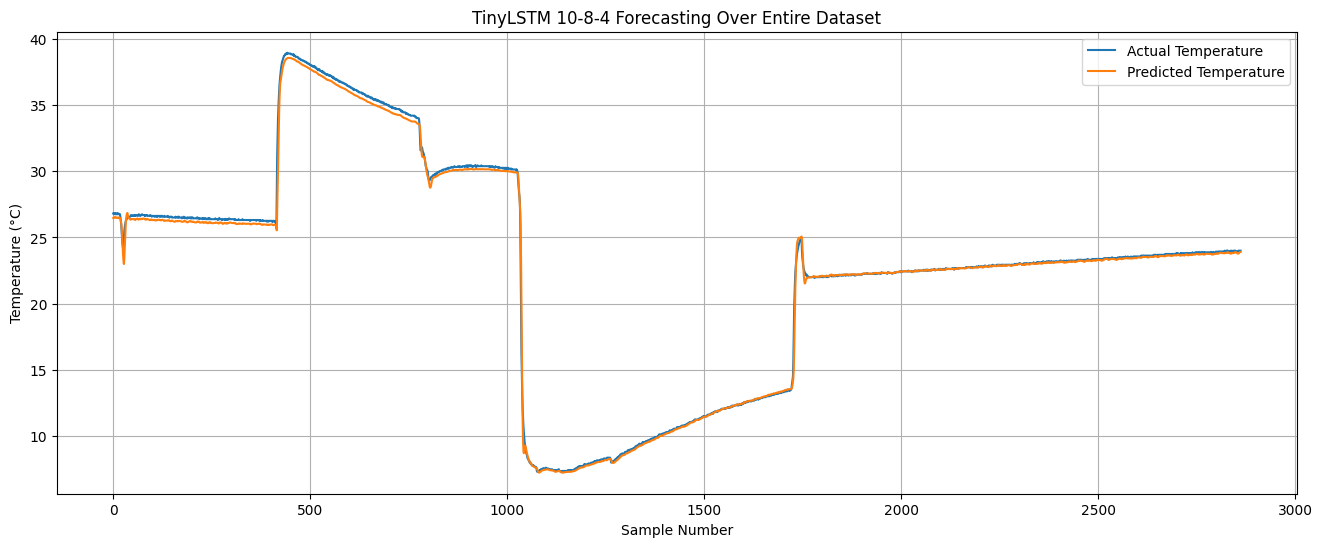

In [23]:
y_all_pred_scaled = model.predict(X)

y_all_actual = scaler.inverse_transform(y)
y_all_pred = scaler.inverse_transform(y_all_pred_scaled)

plt.figure(figsize=(16,6))

plt.plot(y_all_actual, label="Actual Temperature")
plt.plot(y_all_pred, label="Predicted Temperature")

plt.title("TinyLSTM 10-8-4 Forecasting Over Entire Dataset")
plt.xlabel("Sample Number")
plt.ylabel("Temperature (°C)")

plt.legend()
plt.grid(True)

plt.show()